In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import distributions

matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

In [2]:
def set_size(width, fraction=1, subplots=(1, 1)):
    """
    Set figure dimensions to avoid scaling in LaTeX.
    This code is from: https://jwalton.info/Embed-Publication-Matplotlib-Latex/

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'thesis':
        width_pt = 426.79135
        width_pt = width_pt / 72.27
    elif width == 'beamer':
        width_pt = 307.28987
        width_pt = width_pt / 72.27
    else:
        width_pt = width

    # Golden ratio to set aesthetic figure height
    # https://disq.us/p/2940ij3
    golden_ratio = (5**.5 - 1) / 2


    fig_width_in = width_pt * fraction
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)


fig_width, fig_height = set_size('thesis')

### Size distributions

In [3]:
radii = distributions.generate_radii(3., 1e1, 1e4, 10000000)

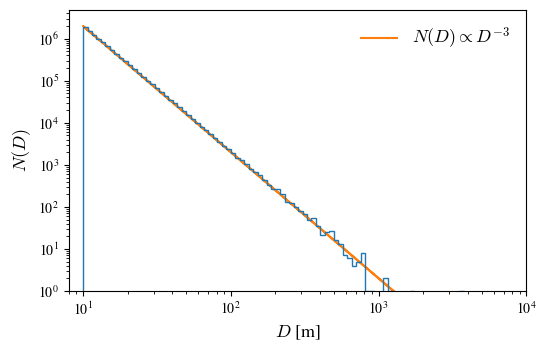

In [4]:
_ = plt.figure(figsize=(fig_width, fig_height))

plt.hist(radii, bins=np.logspace(1, 4, 100), histtype='step', zorder=4)
plt.plot(radii, 2e9 * radii ** -3, label=r'$N(D)\propto D^{-3}$', zorder=1)

plt.xlabel(r'$D$ [m]', fontsize=13)
plt.ylabel(r'$N(D)$', fontsize=13)

plt.xscale('log')
plt.yscale('log')

plt.xlim(8e0, 1e4)
plt.ylim(1, )

plt.legend(fontsize=13, frameon=False)

plt.show()

### Velocity distributions

In [5]:
vels = distributions.generate_velocities(1000000)

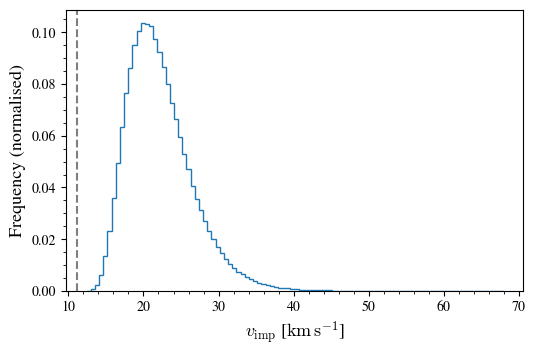

In [6]:
_ = plt.figure(figsize=(fig_width, fig_height))

plt.hist(vels, bins=100, histtype='step', density=True, zorder=4)

plt.axvline(11.19, ls='--', c='tab:gray')

plt.xlabel(r'$v_{\rm imp}$ [${\rm km\,s}^{-1}$]', fontsize=13)
plt.ylabel(r'Frequency (normalised)', fontsize=13)

plt.minorticks_on()

plt.show()

### Angle distributions

In [7]:
angles = distributions.generate_angles(1000000)

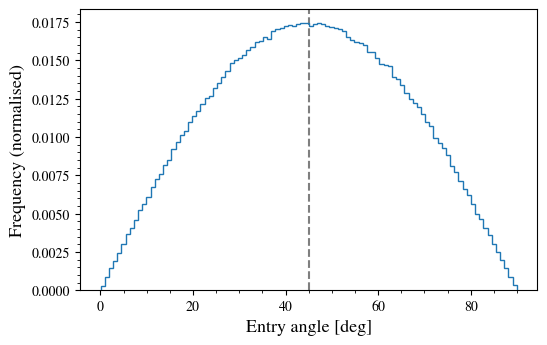

In [8]:
_ = plt.figure(figsize=(fig_width, fig_height))

plt.hist(angles * 180 / np.pi, bins=100, histtype='step', density=True, zorder=4)

plt.axvline(45, ls='--', c='tab:gray')

plt.xlabel(r'Entry angle [deg]', fontsize=13)
plt.ylabel(r'Frequency (normalised)', fontsize=13)

plt.minorticks_on()

plt.show()